# Performing WPT and visualise statistical metrics of nodes using a graph
Here we use a graph presentation to display the results of WPT.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:

%matplotlib inline
sys.path.append("..")

from wavelet_transform.utils import synthetic_data as sd
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.utils.extensions import sci_form

import matplotlib.pyplot as plt
import scipy.signal as sig

import networkx as nx
import pandas as pd

### Parameters

Specify parameters for synthetic data and wavelet transform

In [3]:
amp_sin_waves = 1  # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6
phase = 0

frequency = 1e6

frequencies = [frequency]  # create list of frequencies for synthetic data
time_period = 1 / frequency
signal_duration = (
    10 * time_period
)  # duration of the signal is 10 times the test frequency
delay = 0  # 2*time_period # signal starts 2 time periods late
end = signal_duration  # 8*time_period # signal ends 2 time periods early

gaussian_noise_std = 1  # set the standard devaition of the noise

# generate data
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, phase, signal_duration, sampling_rate, delay, end
)

# add noise
gaussian_noise = sd.noise(gaussian_noise_std, signal_duration, sampling_rate)
data += gaussian_noise
data = sig.windows.hann(len(data)) * data

# transform parameters
levels = 4
db_order = 20
wavelet = f"db{db_order}"
mode = "symmetric"

### Performing WP transform



In [4]:
# transform
transform_object = wpt.dwpt(data, levels, wavelet, "constant")
final_level_nodes = transform_object.get_level(levels)
dwt_nodes = (
    transform_object.dwt_results()
)  # the dwt results can be extracted from the dwpt

# calculate energy
transform_object.calc_frequencies(sampling_rate)

In [5]:
# set title
f = sci_form(frequency)
title = f"- signal frequency: \n{f} Hz"

Wavelet transform

In [6]:
# Set display options
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns


# WPT transform
tr_obj = wpt.dwpt(data, levels, wavelet, mode)
tr_obj.calc_frequencies(sampling_rate)

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

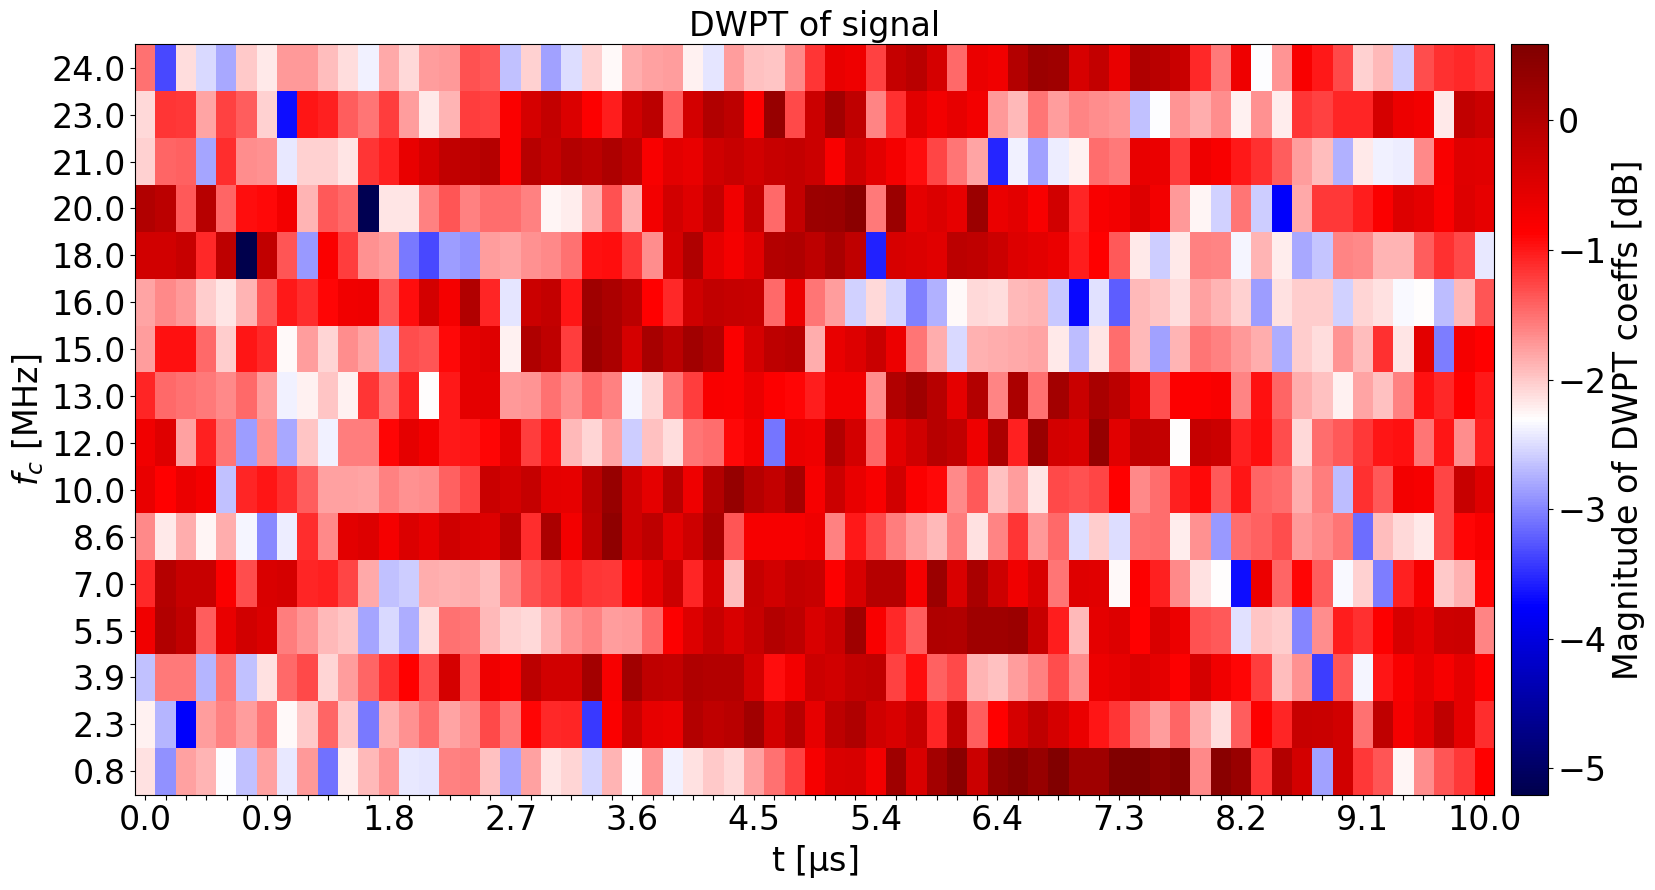

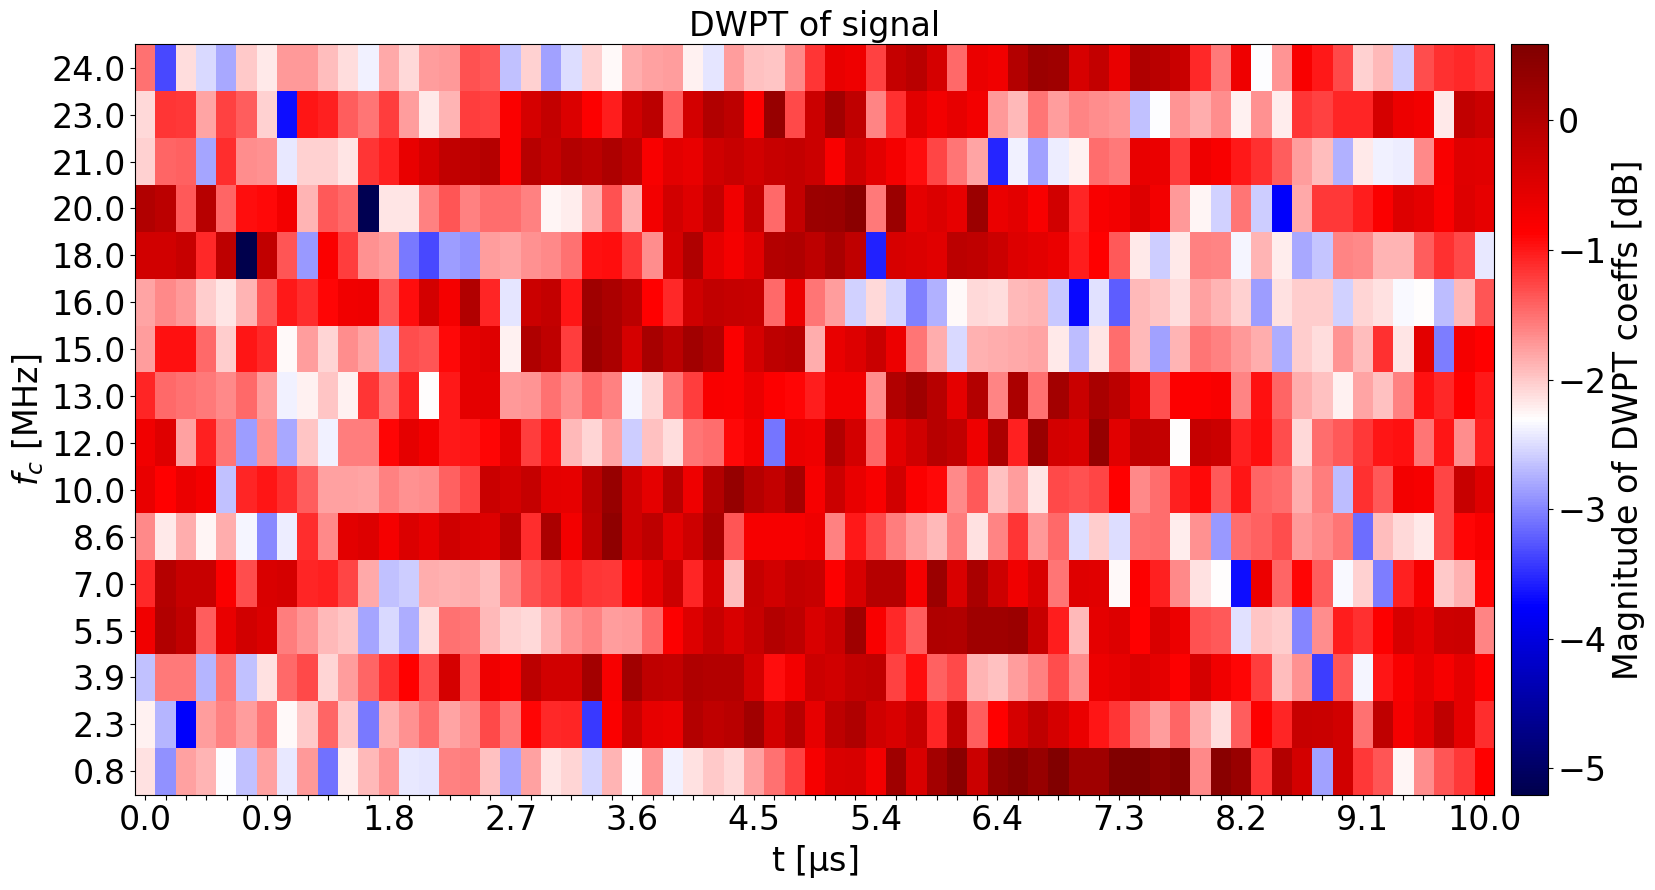

In [7]:
plot.heisenberg(tr_obj, max(t_plot))

## Defining the nodes and edges for the graph representing the WPT

In [8]:
graph_nodes = []
graph_edges = []

for i in range(levels, -1, -1):
    for _, row in tr_obj.info(level=i, order="natural").iterrows():
        node_number = row["node number"]
        energy = row["energy"]
        graph_nodes.append(((i, node_number), {"energy": energy}))
        graph_edges.append(((i, node_number), (i - 1, node_number // 2)))

we need to delete the redundant node (0,-1) created in the last iteration of the for loop above and reverse the orders of the nodes and edges to sort them in an ascending order.

In [9]:
del graph_edges[-1]
graph_nodes.reverse()
graph_edges.reverse()

Defining an empty graph object with `DiGraph` function:

In [10]:
G = nx.DiGraph()

Adding nodes and edges to the graph object

In [11]:
G.add_nodes_from(graph_nodes)
G.add_edges_from(graph_edges)

Plotting the graph below, using `graphviz_layout` function to format the layout

In [12]:
from networkx.drawing.nx_agraph import graphviz_layout

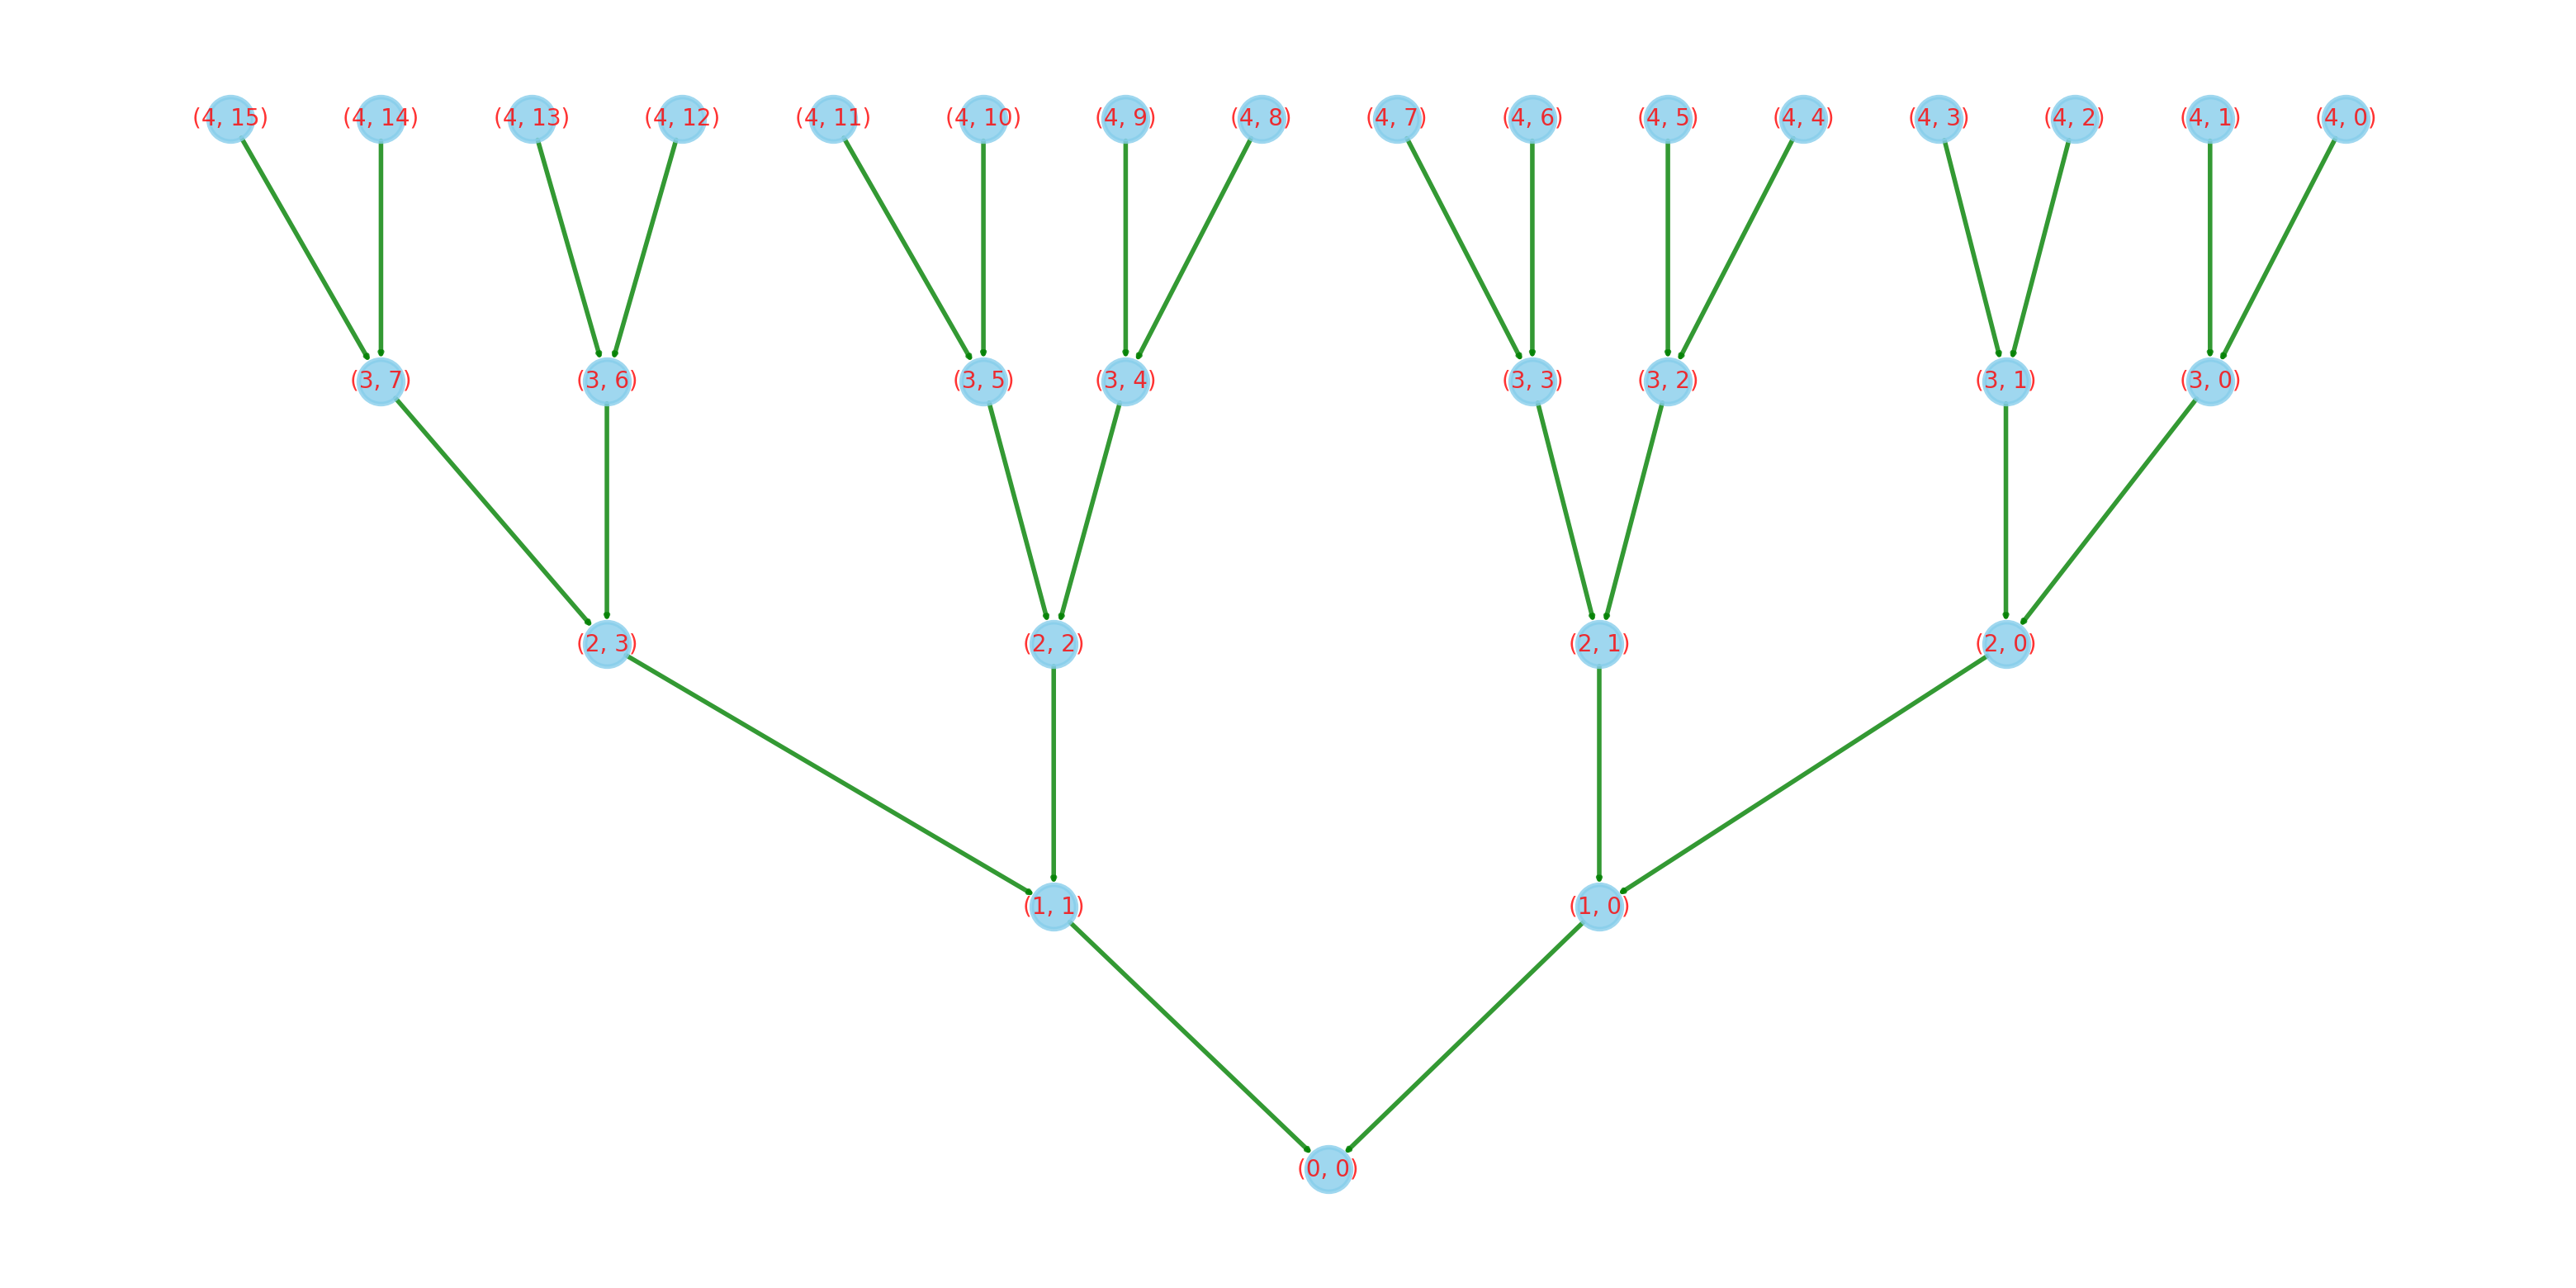

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(40, 20))
nx.draw(
    G,
    pos = graphviz_layout(G,prog = "dot"),
    ax=ax,
    arrowsize=5,
    verticalalignment="center",
    font_size=20,
    font_color="red",
    with_labels=True,
    node_size=1500, node_color="skyblue", node_shape="o", alpha=0.8, linewidths=4,
    width=4, edge_color="green", style="solid"
)  # pos=pos_nodes,
plt.show()

We can reproduce the same graph but weight each node depending on their attributes, e.g. the value of energy at each node

In [14]:
print([k for k in G])

[(0, 0), (1, 1), (1, 0), (2, 3), (2, 2), (2, 1), (2, 0), (3, 7), (3, 6), (3, 5), (3, 4), (3, 3), (3, 2), (3, 1), (3, 0), (4, 15), (4, 14), (4, 13), (4, 12), (4, 11), (4, 10), (4, 9), (4, 8), (4, 7), (4, 6), (4, 5), (4, 4), (4, 3), (4, 2), (4, 1), (4, 0)]


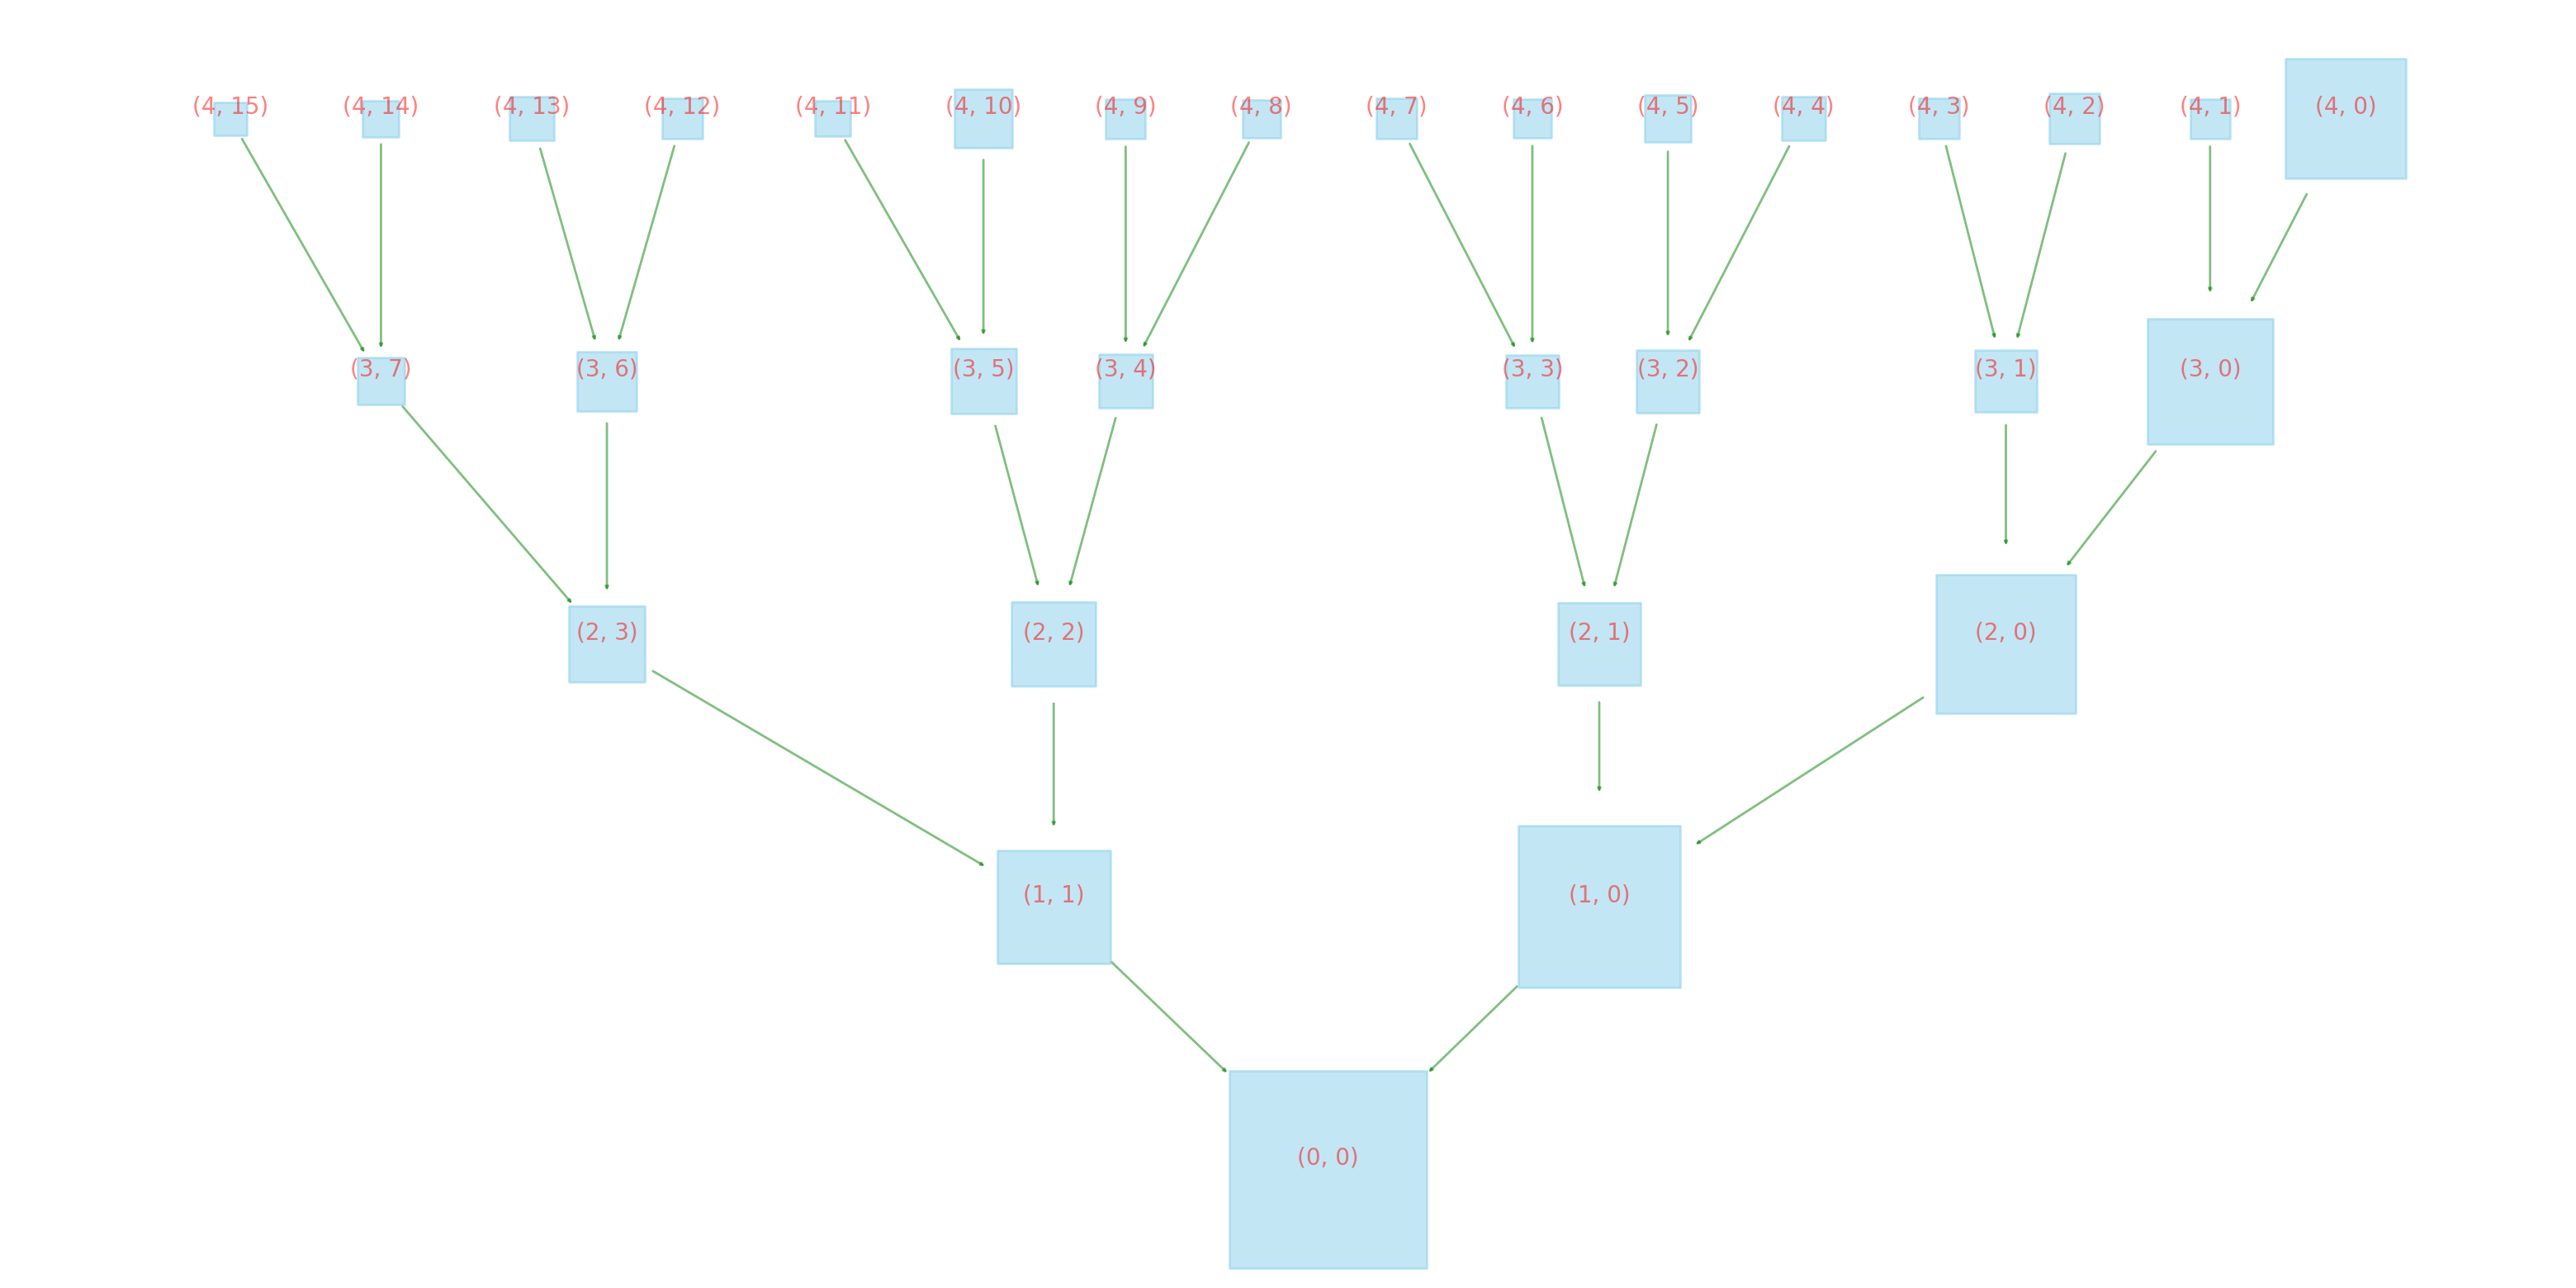

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(40, 20))
nx.draw(
    G,
    pos = graphviz_layout(G,prog = "dot"),
    ax=ax,
    arrowsize=5,
    verticalalignment="bottom",
    font_size=20,
    font_color="red",
    with_labels=True,
    node_size=[1E2 * nx.get_node_attributes(G, "energy")[v] for v in G],
    node_color="skyblue", node_shape="s", alpha=0.5, linewidths=2,
    width=2, edge_color="green", style="solid"
)  # pos=pos_nodes,
plt.show()
